In [52]:
import sqlite3
import datetime
from datetime import timedelta, datetime
import pandas as pd
import datetime as dt

import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, r2_score


def read_database(db_path, table_name='itin'):
    conn = sqlite3.connect(db_path)
    cursor = conn.cursor()

    cursor.execute(f'SELECT * FROM {table_name}')
    rows = cursor.fetchall()
    
    data = pd.DataFrame(rows, columns=[col[0] for col in cursor.description])

    conn.close()
    return data

def filter_data(data, flight_number = None, date_till = None):
    if flight_number:
        data = data[data['itinerary_id'].str.contains(f'{flight_number}-', na=False)]
    if date_till:
        print(date_till)
        data['departure_date'] = pd.to_datetime(data['departure_date'], errors='coerce')
        data = data[data['departure_date'] <= date_till]
    
    return data



## Load and Proccess the Data


In [2]:
itin_df = read_database('flights.db')
legs_df = read_database('flights.db', table_name='legs')
prices_df = read_database('flights.db', table_name='prices')


In [3]:
# Filter itineraries for a specific flight number and date until today
filtered_itin_df = filter_data(itin_df, date_till=dt.datetime.today() - timedelta(days=1))

filtered_legs_df = legs_df[legs_df['airline_name'] == 'Ryanair']

# Merge the filtered itineraries with legs and prices dataframes
merged_df = pd.merge(filtered_itin_df, filtered_legs_df, on='itinerary_id', how='inner')
merged_df2 = pd.merge(merged_df, prices_df, on='itinerary_id', how='left')



2025-07-28 14:15:03.592100


## Cleaning and preparation of the merged dataframe



In [158]:
# Feature engineering
df = merged_df2.copy().loc[:, ['itinerary_id', 'src', 'dst', 'departure_datetime', 'arrival_datetime', 'region_from', 'region_to', 'days_to_departure', 'aircraft','emissions', 'price_datetime', 'day_of_week', 'price', 'travel_time', 'is_best']]

# 1. Drop rows with missing values in 'departure_datetime', 'arrival_datetime', 'price_datetime', and 'price'
df_drop = df.dropna(subset=['departure_datetime', 'arrival_datetime', 'price_datetime', 'price', 'travel_time'])

# 2. Count the number of records for each itinerary_id
itinerary_counts = df_drop['itinerary_id'].value_counts()   
# Remove itineraries with less than 3 records
valid_itineraries = itinerary_counts[itinerary_counts >= 25].index
proccessed_df = df_drop[df_drop['itinerary_id'].isin(valid_itineraries)]


print(proccessed_df.shape)
# 2. Convert departure_datetime and arrival_datetime to datetime objects
proccessed_df['departure_datetime'] = pd.to_datetime(proccessed_df['departure_datetime'], format='mixed')
proccessed_df['arrival_datetime'] = pd.to_datetime(proccessed_df['arrival_datetime'], format='mixed')
proccessed_df['price_datetime'] = pd.to_datetime(proccessed_df['price_datetime'], format='mixed')

# 3. Extract features from departure_datetime
proccessed_df['days_to_departure'] = (
   proccessed_df['departure_datetime'].dt.date - proccessed_df['price_datetime'].dt.date
).apply(lambda x: x.days)

proccessed_df['is_weekend'] = proccessed_df['departure_datetime'].dt.dayofweek >= 4  # 5=Saturday, 6=Sunday
proccessed_df['is_weekend'] = proccessed_df['is_weekend'].astype(int)
proccessed_df['travel_time'] = proccessed_df['travel_time'].astype(int)


# 3.2. Extract date and time features
#proccessed_df['dep_day'] = proccessed_df['departure_datetime'].dt.day

proccessed_df['dayofweek'] = proccessed_df['departure_datetime'].dt.dayofweek
proccessed_df['month'] = proccessed_df['departure_datetime'].dt.month
proccessed_df['dayofyear'] = proccessed_df['departure_datetime'].dt.dayofyear
proccessed_df['dayofmonth'] = proccessed_df['departure_datetime'].dt.day


bins = [0, 6, 12, 17, 24]
labels = ['Night', 'Morning', 'Afternoon', 'Evening']

proccessed_df['hour'] = pd.cut(proccessed_df['departure_datetime'].dt.hour, bins=bins, labels=labels, right=False, include_lowest=True)
proccessed_df['price_hour'] = pd.cut(proccessed_df['price_datetime'].dt.hour, bins=bins, labels=labels, right=False, include_lowest=True)



# Implementing Lagged Features
proccessed_df = proccessed_df.sort_values(by=['itinerary_id', 'days_to_departure'], ascending=[True, False])
proccessed_df['price_lag_1'] = proccessed_df.groupby('itinerary_id')['price'].shift(1).fillna(method='bfill')
proccessed_df['price_lag_7'] = proccessed_df.groupby('itinerary_id')['price'].shift(7).fillna(proccessed_df.groupby('itinerary_id')['price'].transform('mean'))


proccessed_df1 = proccessed_df.loc[:, ['itinerary_id', 'src', 'dst', 'price_datetime', 'price_lag_1','price_lag_7','days_to_departure', 'price','hour', 'dayofweek', 'dayofmonth', 'month', 'dayofyear', 'is_weekend', 'price_hour', 'is_best', 'travel_time']]

(4591, 15)


C:\Users\pinyc\AppData\Local\Temp\ipykernel_12980\645792434.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  proccessed_df['departure_datetime'] = pd.to_datetime(proccessed_df['departure_datetime'], format='mixed')
C:\Users\pinyc\AppData\Local\Temp\ipykernel_12980\645792434.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  proccessed_df['arrival_datetime'] = pd.to_datetime(proccessed_df['arrival_datetime'], format='mixed')
C:\Users\pinyc\AppData\Local\Temp\ipykernel_12980\645792434.py:18: SettingWith

In [160]:
proccessed_df1.shape

(4591, 17)

In [ ]:
data = proccessed_df1.copy()

# Encode categorical variables
categorical_cols = ['hour', 'price_hour', 'src', 'dst']
encoders = {}

# Fit and transform each categorical column, saving the encoder
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col].astype(str))
    encoders[col] = le




X = data.drop(columns=['price', 'is_best', 'price_datetime'])
y = data['price']

# Split the dataset into training and tessetst  (80-20 split)
train_flights = data[data['itinerary_id'].isin(data['itinerary_id'].unique()[:int(0.8*len(data['itinerary_id'].unique()))])]
test_flights = data[~data['itinerary_id'].isin(train_flights['itinerary_id'].unique())]

X_train, y_train = X.loc[train_flights.index], y.loc[train_flights.index]
X_test, y_test = X.loc[test_flights.index], y.loc[test_flights.index]

print(X_train.head())   
# Drop the 'itinerary_id' column from X_train and X_test
X_train = X_train.drop(columns=['itinerary_id'])
X_test = X_test.drop(columns=['itinerary_id'])



                            itinerary_id  src  dst  price_lag_1  price_lag_7  \
106848  FR10-2025-07-21T06:00:00-DUB-MAD    8   15       188.49   228.480625   
106849  FR10-2025-07-21T06:00:00-DUB-MAD    8   15       188.49   228.480625   
106850  FR10-2025-07-21T06:00:00-DUB-MAD    8   15       205.24   228.480625   
106851  FR10-2025-07-21T06:00:00-DUB-MAD    8   15       181.99   228.480625   
106852  FR10-2025-07-21T06:00:00-DUB-MAD    8   15       181.99   228.480625   

        days_to_departure  hour  dayofweek  dayofmonth  month  dayofyear  \
106848                 26     2          0          21      7        202   
106849                 22     2          0          21      7        202   
106850                 20     2          0          21      7        202   
106851                 18     2          0          21      7        202   
106852                 16     2          0          21      7        202   

        is_weekend  price_hour  travel_time  
106848          

In [148]:
print(X_train.head())

        src  dst  price_lag_1  price_lag_7  days_to_departure  hour  \
106848    8   15       188.49   228.480625                 26     2   
106849    8   15       188.49   228.480625                 22     2   
106850    8   15       205.24   228.480625                 20     2   
106851    8   15       181.99   228.480625                 18     2   
106852    8   15       181.99   228.480625                 16     2   

        dayofweek  dayofmonth  month  dayofyear  is_weekend  price_hour  \
106848          0          21      7        202           0           0   
106849          0          21      7        202           0           0   
106850          0          21      7        202           0           1   
106851          0          21      7        202           0           2   
106852          0          21      7        202           0           0   

        travel_time  
106848          155  
106849          155  
106850          155  
106851          155  
106852      

In [149]:
reg = xgb.XGBRegressor(learning_rate = 0.1, max_depth = 7, subsample = 0.7, n_estimators=1000)


# Create sample weights (e.g., linearly increasing with days_to_departure)
weights = X.loc[X_train.index, 'days_to_departure'] / X['days_to_departure'].max()
print(f"Sample weights range: {weights.min()} to {weights.max()}")

# Fit the model with sample weights
reg.fit(X_train, y_train,
        sample_weight=weights,
        verbose=True)


# Print feature importances
print("Feature importances:")
for feature, importance in zip(X_train.columns, reg.feature_importances_):
    print(f"{feature}: {importance:.4f}")

Sample weights range: 0.011764705882352941 to 1.0
Feature importances:
src: 0.0168
dst: 0.0186
price_lag_1: 0.8115
price_lag_7: 0.0174
days_to_departure: 0.0192
hour: 0.0128
dayofweek: 0.0144
dayofmonth: 0.0157
month: 0.0225
dayofyear: 0.0176
is_weekend: 0.0000
price_hour: 0.0153
travel_time: 0.0183


In [150]:
y_pred = reg.predict(X_test)

comparison_df = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred}, index=y_test.index)
print(comparison_df.tail(10))
mae = (comparison_df['Actual'] - comparison_df['Predicted']).abs().mean()
r2 = r2_score(y_test, y_pred)

print(f"Mean absolute error: {mae}")
print(f"Model accuracy: {r2}")


        Actual   Predicted
115292   56.25   86.537025
115293   54.19   73.455879
115294   33.43   82.833115
115295   38.96   64.343246
115296   30.84   56.749283
115297   40.58   49.993977
115298   39.09   74.707390
115299   63.13   72.164932
115300   63.06  118.345093
115301   67.34  120.037834
Mean absolute error: 17.954709456367812
Model accuracy: 0.882164018871971


In [152]:
# Compare predicted vs actual values for individual flight

def single_flight(date_time,src, dst, travel_time, flight_number=None):
    date, time = date_time.split(' ')
    date = datetime.strptime(date, '%Y-%m-%d')
    print(date)
    time = datetime.strptime(time, '%H:%M').time()
    # Example: create a test dictionary for a single flight
    flight_params = {
        'itinerary_id': f'{flight_number}-{date.strftime("%Y-%m-%d")}T{time.strftime("%H:%M:%S")}-{src}-{dst}',
        'src': encoders['src'].transform([src])[0],
        'dst': encoders['dst'].transform([dst])[0],
        'hour': encoders['hour'].transform(['Evening'])[0],
        'dayofweek': date.weekday(),  # Sunday (=0)
        'dayofmonth': date.day, 
        'month': date.month,
        'dayofyear': date.timetuple().tm_yday,
        'is_weekend': 0 if date.weekday() <= 4 else 1,  # Saturday or Sunday
        'price_hour': encoders['price_hour'].transform(['Afternoon'])[0],
        'travel_time': travel_time,  # example value, adjust as needed
    }
    



    test_flight = pd.read_csv('test_flight.csv')
    test_rows = []
    for row in test_flight.itertuples(index=False):
        ft = flight_params.copy()
        ft['days_to_departure'] = row.Date + 2
        ft['price'] = row.Price
        test_rows.append(ft)

    # Create DataFrame
    test_df = pd.DataFrame(test_rows)

    return test_df

test_flight = single_flight('2025-07-06 12:30', 'KUN', 'MAD', 250 )





2025-07-06 00:00:00


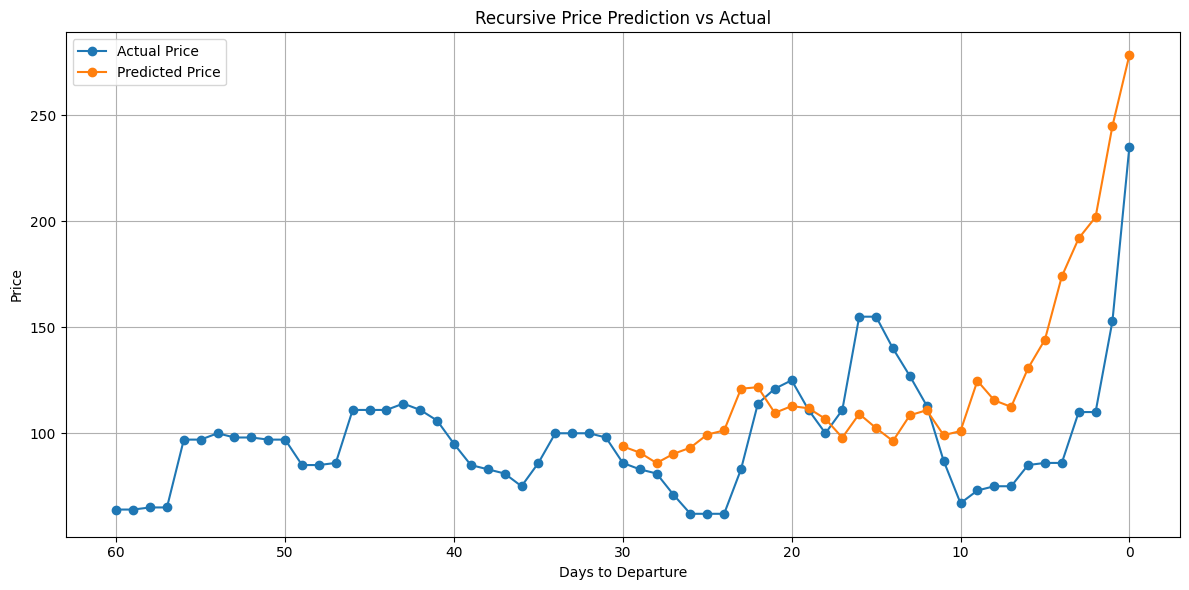

MAE: 34.76, RMSE: 1913.78


In [153]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

def single_flight(date_time, src, dst, travel_time, flight_number=None):
    date, time = date_time.split(' ')
    date = datetime.strptime(date, '%Y-%m-%d')
    time = datetime.strptime(time, '%H:%M').time()

    flight_params = {
        'itinerary_id': f'{flight_number}-{date.strftime("%Y-%m-%d")}T{time.strftime("%H:%M:%S")}-{src}-{dst}',
        'src': encoders['src'].transform([src])[0],
        'dst': encoders['dst'].transform([dst])[0],
        'hour': encoders['hour'].transform(['Evening'])[0],
        'dayofweek': date.weekday(),
        'dayofmonth': date.day, 
        'month': date.month,
        'dayofyear': date.timetuple().tm_yday,
        'is_weekend': 0 if date.weekday() <= 4 else 1,
        'price_hour': encoders['price_hour'].transform(['Afternoon'])[0],
        'travel_time': travel_time,
    }

    test_flight = pd.read_csv('test_flight.csv')  # contains Date, Price
    test_rows = []
    for row in test_flight.itertuples(index=False):
        ft = flight_params.copy()
        ft['days_to_departure'] = row.Date
        ft['price'] = row.Price
        test_rows.append(ft)

    return pd.DataFrame(test_rows)

# --- Load data ---
df = single_flight('2025-07-06 12:30', 'KUN', 'MAD', 250)
df = df.sort_values(by='days_to_departure', ascending=False).reset_index(drop=True)

# --- Add lag features ---
def add_lags(df):
    df['price_lag_1'] = df['price'].shift(1)
    df['price_lag_7'] = df['price'].shift(7)
    return df

df = add_lags(df)

# --- Split observed and future ---
observed = df[df['days_to_departure'] > 30].dropna().copy()  # scraped observed
future_real = df[df['days_to_departure'] <= 30].copy()       # true future prices to compare

# --- Start recursive prediction ---
features =  ['src', 'dst', 'price_lag_1', 'price_lag_7', 'days_to_departure', 'hour', 'dayofweek', 'dayofmonth', 'month', 'dayofyear', 'is_weekend', 'price_hour', 'travel_time']
last_rows = observed.copy()
predicted_rows = []

for target_day in range(30, -1, -1):  # days_to_departure = 19 → 0
    base_row = last_rows.iloc[-1].copy()
    new_row = base_row.copy()
    new_row['days_to_departure'] = target_day
    new_row['price_lag_1'] = last_rows.iloc[-1]['price']
    new_row['price_lag_7'] = last_rows.iloc[-7]['price'] if len(last_rows) >= 7 else last_rows['price'].mean()

    input_df = pd.DataFrame([new_row[features]])
    predicted_price = reg.predict(input_df)[0]

    new_row['price'] = predicted_price
    predicted_rows.append(new_row)
    last_rows = pd.concat([last_rows, pd.DataFrame([new_row])], ignore_index=True)

predicted_df = pd.DataFrame(predicted_rows)

# --- Merge prediction with actual ---
merged = predicted_df[['days_to_departure', 'price']].merge(
    future_real[['days_to_departure', 'price']],
    on='days_to_departure',
    how='left',
    suffixes=('_predicted', '_actual')
).sort_values(by='days_to_departure', ascending=False)

# --- Plot ---
plt.figure(figsize=(12,6))
plt.plot(df['days_to_departure'], df['price'], label='Actual Price', marker='o')
plt.plot(merged['days_to_departure'], merged['price_predicted'], label='Predicted Price', marker='o')
plt.xlabel('Days to Departure')
plt.ylabel('Price')
plt.title('Recursive Price Prediction vs Actual')
plt.gca().invert_xaxis()
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# --- Optional: error metrics ---
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae = mean_absolute_error(merged['price_actual'], merged['price_predicted'])
rmse = mean_squared_error(merged['price_actual'], merged['price_predicted'])
print(f"MAE: {mae:.2f}, RMSE: {rmse:.2f}")


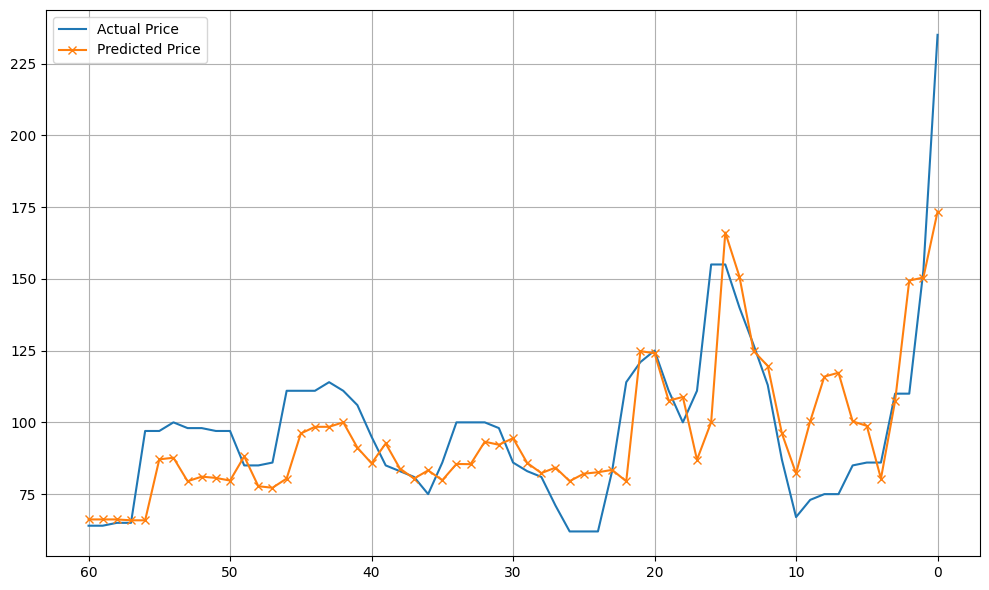

In [82]:
# Make plots in reverse 
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 6))
plt.plot(comparison_df.index, comparison_df['Actual'], label='Actual Price', marker='')
plt.plot(comparison_df.index, comparison_df['Predicted'], label='Predicted Price', marker='x')

plt.legend()
plt.grid()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()# Invert x-axis to show days to departure in reverse order



In [161]:
def price_will_go_down(df):
    # Sort by flight_id and days_to_departure
    df = df.sort_values(['itinerary_id', 'days_to_departure'], ascending=[True, False])
    
    # Calculate minimum future price within each flight
    df['min_future_price'] = df.groupby('itinerary_id')['price'].transform(lambda x: x.shift(-1).min())
    
    # Set label to 1 if current price is > 10% above min future price, 0 otherwise
    df['label'] = ((df['price'] > df['min_future_price'] * 1.10) & df['min_future_price'].notna()).astype(int)
    
    # Drop rows where min_future_price is NaN (last row of each flight)
    df = df.dropna(subset=['min_future_price'])
    
    return df

In [165]:
data = proccessed_df1.copy()

data = price_will_go_down(data)
# Prepare features and target


categorical_cols = ['hour', 'price_hour', 'src', 'dst']
encoders = {}

# Fit and transform each categorical column, saving the encoder
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col].astype(str))
    encoders[col] = le


X = data.drop(columns=['price_datetime', 'label' ,'price_lag_7', 'min_future_price'])
y = data['label']
print(X.head())

# Flight-wise train-test split
train_flights = data[data['itinerary_id'].isin(data['itinerary_id'].unique()[:int(0.8*len(data['itinerary_id'].unique()))])]
test_flights = data[~data['itinerary_id'].isin(train_flights['itinerary_id'].unique())]
X_train, y_train = X.loc[train_flights.index], y.loc[train_flights.index]
X_test, y_test = X.loc[test_flights.index], y.loc[test_flights.index]

X_test = X_test.drop(columns=['itinerary_id'])
X_train = X_train.drop(columns=['itinerary_id'])

X = X.drop(columns=['itinerary_id'])


# Train the model
import xgboost as xgb
reg = xgb.XGBClassifier(learning_rate=0.1, max_depth=7, subsample=0.8, n_estimators=1000)
reg.fit(X_train, y_train,
        verbose=True)

                           itinerary_id  src  dst  price_lag_1  \
538  FR1006-2025-07-21T22:00:00-OTP-STN   11   11        28.93   
539  FR1006-2025-07-21T22:00:00-OTP-STN   11   11        28.93   
540  FR1006-2025-07-21T22:00:00-OTP-STN   11   11        27.62   
541  FR1006-2025-07-21T22:00:00-OTP-STN   11   11        26.82   
542  FR1006-2025-07-21T22:00:00-OTP-STN   11   11        26.82   

     days_to_departure  price  hour  dayofweek  dayofmonth  month  dayofyear  \
538                 78  28.93     1          0          21      7        202   
539                 71  27.62     1          0          21      7        202   
540                 64  26.82     1          0          21      7        202   
541                 64  26.82     1          0          21      7        202   
542                 63  26.82     1          0          21      7        202   

     is_weekend  price_hour  is_best  travel_time  
538           0           0        0          205  
539           0   

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [166]:
y_pred = reg.predict(X_test)

comparison_df = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred}, index=y_test.index)

print(comparison_df.tail(10))



       Actual  Predicted
67070       1          1
67071       0          0
67072       1          1
67073       1          1
67074       1          1
67075       1          1
67076       1          1
67077       1          1
67078       1          1
67079       1          1


In [167]:
from sklearn.metrics import classification_report
print("Classification Report:\n", classification_report(y_test, y_pred))


from sklearn.model_selection import cross_val_score
scores = cross_val_score(reg, X, y, cv=5, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.2f} (+/- {scores.std() * 2:.2f})")


Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.53      0.66       175
           1       0.90      0.98      0.94       750

    accuracy                           0.90       925
   macro avg       0.89      0.75      0.80       925
weighted avg       0.90      0.90      0.89       925

Cross-Validation Accuracy: 0.87 (+/- 0.04)
